In [6]:
%pip -q install "transformers==4.57.3"

## Читаем golden set

In [7]:
import json
from pathlib import Path

with Path("/content/golden_set.jsonl").open(encoding="utf-8") as file:
    rows = [json.loads(line) for line in file if line.strip()]

golden = {int(row["photo_id"]): row for row in rows}

## Grounding DINO

In [ ]:
import json
from io import BytesIO
from pathlib import Path
from tempfile import mkdtemp
from time import perf_counter

import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image, ImageOps
from requests.adapters import HTTPAdapter
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor, __version__
from urllib3.util import Retry


MODEL_ID = "IDEA-Research/grounding-dino-tiny"
PROMPT = "butterfly. moth."
BOX_THRESHOLD = 0.35
TEXT_THRESHOLD = 0.25


def predict(model, processor, image):
    """Возвращает рамки в формате golden set с координатами от 0 до 1."""
    width, height = image.size
    inputs = processor(images=image, text=PROMPT, return_tensors="pt").to("cuda")

    with torch.inference_mode():
        result = processor.post_process_grounded_object_detection(
            model(**inputs),
            inputs.input_ids,
            threshold=BOX_THRESHOLD,
            text_threshold=TEXT_THRESHOLD,
            target_sizes=[(height, width)],
        )[0]

    boxes = []
    for x1, y1, x2, y2 in result["boxes"].cpu().tolist():
        left, right = max(0, x1 / width), min(1, x2 / width)
        top, bottom = max(0, y1 / height), min(1, y2 / height)
        if left < right and top < bottom:
            boxes.append({
                "left": left, "top": top,
                "width": right - left, "height": bottom - top,
            })
    return boxes


def iou(a, b):
    intersection_width = min(
        a["left"] + a["width"], b["left"] + b["width"]
    ) - max(a["left"], b["left"])
    intersection_height = min(
        a["top"] + a["height"], b["top"] + b["height"]
    ) - max(a["top"], b["top"])

    intersection = max(0, intersection_width) * max(0, intersection_height)
    union = a["width"] * a["height"] + b["width"] * b["height"] - intersection
    return intersection / union if union > 0 else 0.0


def evaluate(golden, predictions):
    """Считает F1 по всем фото с сопоставлением рамок один к одному."""
    matrices = [
        np.array([[iou(p, g) for g in row["boxes"]] for p in pred["boxes"]])
        for row, pred in zip(golden, predictions)
        if row["boxes"] and pred["boxes"]
    ]
    n_gold = sum(len(row["boxes"]) for row in golden)
    n_pred = sum(len(row["boxes"]) for row in predictions)

    metrics = []
    for threshold in (0.50, 0.75):
        tp = 0
        for matrix in matrices:
            allowed = (matrix >= threshold).astype(np.int8)
            rows, cols = linear_sum_assignment(allowed, maximize=True)
            tp += int(allowed[rows, cols].sum())

        metrics.append({
            "IoU": threshold,
            "F1": 2 * tp / (n_gold + n_pred),
            "Precision": tp / n_pred if n_pred else 0.0,
            "Recall": tp / n_gold,
            "TP": tp, "FP": n_pred - tp, "FN": n_gold - tp,
        })
    return metrics


def run_grounding_dino():
    if not torch.cuda.is_available():
        raise RuntimeError("Выбери GPU T4 в настройках среды Colab.")

    with Path("/content/golden_set.jsonl").open(encoding="utf-8") as file:
        golden = [json.loads(line) for line in file if line.strip()]
    assert len(golden) == len({row["photo_id"] for row in golden}) == 400

    processor = AutoProcessor.from_pretrained(MODEL_ID)
    model = AutoModelForZeroShotObjectDetection.from_pretrained(
        MODEL_ID, use_safetensors=True
    ).to("cuda").eval()

    run_dir = Path(mkdtemp(prefix="grounding_dino_", dir="/content"))
    print(f"Результаты будут в {run_dir}", flush=True)
    config = {
        "model": MODEL_ID, "prompt": PROMPT,
        "box_threshold": BOX_THRESHOLD, "text_threshold": TEXT_THRESHOLD,
        "input_size": dict(processor.image_processor.size),
        "transformers": __version__, "gpu": torch.cuda.get_device_name(0),
    }
    (run_dir / "config.json").write_text(json.dumps(config, indent=2))

    predictions = []
    with requests.Session() as session, (run_dir / "predictions.jsonl").open(
        "w", encoding="utf-8"
    ) as file:
        session.mount("https://", HTTPAdapter(max_retries=Retry(
            total=2, backoff_factor=0.5, status_forcelist=(429, 500, 502, 503, 504)
        )))

        for row in tqdm(golden, desc="Grounding DINO", unit="фото"):
            record = {"photo_id": row["photo_id"], "boxes": [], "error": None}
            try:
                response = session.get(row["image_url"], timeout=(8, 25))
                response.raise_for_status()
                with Image.open(BytesIO(response.content)) as source:
                    image = ImageOps.exif_transpose(source).convert("RGB")
            except (requests.RequestException, OSError) as error:
                record["error"] = str(error)
            else:
                start = perf_counter()
                record["boxes"] = predict(model, processor, image)
                record["inference_seconds"] = perf_counter() - start

            predictions.append(record)
            file.write(json.dumps(record, ensure_ascii=False) + "\n")
            file.flush()

    failed = [row["photo_id"] for row in predictions if row["error"] is not None]
    if failed:
        raise RuntimeError(f"Ошибки на {len(failed)} фото. Первые ID: {failed[:10]}")

    metrics = evaluate(golden, predictions)
    (run_dir / "metrics.json").write_text(json.dumps(metrics, indent=2))
    display(pd.DataFrame(metrics).round(4))


run_grounding_dino()

Результаты будут в /content/grounding_dino_ps1xfe9u


Grounding DINO:   0%|          | 0/400 [00:00<?, ?фото/s]

,IoU,F1,Precision,Recall,TP,FP,FN
0,0.50,0.5090,0.3677,0.8268,296,509,62
1,0.75,0.4643,0.3354,0.7542,270,535,88


## OWLv2

In [ ]:
import json
from io import BytesIO
from pathlib import Path
from tempfile import mkdtemp
from time import perf_counter

import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image, ImageOps
from requests.adapters import HTTPAdapter
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor, __version__
from urllib3.util import Retry


MODEL_ID = "google/owlv2-base-patch16"
PROMPT = "butterfly. moth"
BOX_THRESHOLD = 0.20


def predict(model, processor, image):
    """Возвращает рамки в формате golden set с координатами от 0 до 1."""
    width, height = image.size
    inputs = processor(images=image, text=[[PROMPT]], return_tensors="pt").to("cuda")
    target_sizes = torch.tensor([(height, width)], device="cuda")

    with torch.inference_mode():
        result = processor.image_processor.post_process_object_detection(
            outputs=model(**inputs),
            threshold=BOX_THRESHOLD,
            target_sizes=target_sizes,
        )[0]

    boxes = []
    for x1, y1, x2, y2 in result["boxes"].cpu().tolist():
        left, right = max(0, x1 / width), min(1, x2 / width)
        top, bottom = max(0, y1 / height), min(1, y2 / height)
        if left < right and top < bottom:
            boxes.append({
                "left": left, "top": top,
                "width": right - left, "height": bottom - top,
            })
    return boxes


def iou(a, b):
    intersection_width = min(
        a["left"] + a["width"], b["left"] + b["width"]
    ) - max(a["left"], b["left"])
    intersection_height = min(
        a["top"] + a["height"], b["top"] + b["height"]
    ) - max(a["top"], b["top"])

    intersection = max(0, intersection_width) * max(0, intersection_height)
    union = a["width"] * a["height"] + b["width"] * b["height"] - intersection
    return intersection / union if union > 0 else 0.0


def evaluate(golden, predictions):
    """Считает F1 по всем фото с сопоставлением рамок один к одному."""
    matrices = [
        np.array([[iou(p, g) for g in row["boxes"]] for p in pred["boxes"]])
        for row, pred in zip(golden, predictions)
        if row["boxes"] and pred["boxes"]
    ]
    n_gold = sum(len(row["boxes"]) for row in golden)
    n_pred = sum(len(row["boxes"]) for row in predictions)

    metrics = []
    for threshold in (0.50, 0.75):
        tp = 0
        for matrix in matrices:
            allowed = (matrix >= threshold).astype(np.int8)
            rows, cols = linear_sum_assignment(allowed, maximize=True)
            tp += int(allowed[rows, cols].sum())

        metrics.append({
            "IoU": threshold,
            "F1": 2 * tp / (n_gold + n_pred),
            "Precision": tp / n_pred if n_pred else 0.0,
            "Recall": tp / n_gold,
            "TP": tp, "FP": n_pred - tp, "FN": n_gold - tp,
        })
    return metrics


def run_owlv2():
    if not torch.cuda.is_available():
        raise RuntimeError("Выбери GPU T4 в настройках среды Colab.")

    with Path("/content/golden_set.jsonl").open(encoding="utf-8") as file:
        golden = [json.loads(line) for line in file if line.strip()]
    assert len(golden) == len({row["photo_id"] for row in golden}) == 400

    processor = AutoProcessor.from_pretrained(MODEL_ID)
    model = AutoModelForZeroShotObjectDetection.from_pretrained(
        MODEL_ID, use_safetensors=True
    ).to("cuda").eval()

    run_dir = Path(mkdtemp(prefix="owlv2_", dir="/content"))
    print(f"Результаты будут в {run_dir}", flush=True)
    config = {
        "model": MODEL_ID, "prompt": PROMPT, "box_threshold": BOX_THRESHOLD,
        "input_size": dict(processor.image_processor.size),
        "transformers": __version__, "gpu": torch.cuda.get_device_name(0),
    }
    (run_dir / "config.json").write_text(json.dumps(config, indent=2))

    predictions = []
    with requests.Session() as session, (run_dir / "predictions.jsonl").open(
        "w", encoding="utf-8"
    ) as file:
        session.mount("https://", HTTPAdapter(max_retries=Retry(
            total=2, backoff_factor=0.5, status_forcelist=(429, 500, 502, 503, 504)
        )))

        for row in tqdm(golden, desc="OWLv2", unit="фото"):
            record = {"photo_id": row["photo_id"], "boxes": [], "error": None}
            try:
                response = session.get(row["image_url"], timeout=(8, 25))
                response.raise_for_status()
                with Image.open(BytesIO(response.content)) as source:
                    image = ImageOps.exif_transpose(source).convert("RGB")
            except (requests.RequestException, OSError) as error:
                record["error"] = str(error)
            else:
                start = perf_counter()
                record["boxes"] = predict(model, processor, image)
                record["inference_seconds"] = perf_counter() - start

            predictions.append(record)
            file.write(json.dumps(record, ensure_ascii=False) + "\n")
            file.flush()

    failed = [row["photo_id"] for row in predictions if row["error"] is not None]
    if failed:
        raise RuntimeError(f"Ошибки на {len(failed)} фото. Первые ID: {failed[:10]}")

    metrics = evaluate(golden, predictions)
    (run_dir / "metrics.json").write_text(json.dumps(metrics, indent=2))
    display(pd.DataFrame(metrics).round(4))


run_owlv2()

Результаты будут в /content/owlv2_i1faa2ja


OWLv2:   0%|          | 0/400 [00:00<?, ?фото/s]

,IoU,F1,Precision,Recall,TP,FP,FN
0,0.50,0.4251,0.2841,0.8436,302,761,56
1,0.75,0.3096,0.2070,0.6145,220,843,138


## Qwen3‑VL‑2B‑Instruct

In [3]:
%pip -q install "transformers==4.57.3" "lm-format-enforcer==0.11.3"

import json
import math
import re
from io import BytesIO
from pathlib import Path
from tempfile import mkdtemp
from time import perf_counter

import numpy as np
import pandas as pd
import requests
import torch
from IPython.display import display
from lmformatenforcer import RegexParser
from lmformatenforcer.integrations.transformers import (
    build_token_enforcer_tokenizer_data,
    build_transformers_prefix_allowed_tokens_fn,
)
from PIL import Image, ImageOps
from requests.adapters import HTTPAdapter
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration, __version__
from urllib3.util import Retry


# Настройки прогона

INPUT_PATH = Path("/content/golden_set.jsonl")
EVALUATE = True
MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"
MAX_IMAGE_EDGE = 1024
MAX_NEW_TOKENS = 2048

RETRY_TOKENS = 4096
RETRY_MAX_BOXES = 64
RETRY_PENALTY = 1.05

PROMPT = '''Find all visible adult butterflies and moths. Return one tight box per individual.
Ignore eggs, caterpillars, pupae, other insects, and shadows.
Return only a JSON array of objects with "label": "butterfly" and
"bbox_2d": [left, top, right, bottom]. Use integer coordinates from 0 to 1000
relative to the full image. Return [] if no target is visible.'''

RETRY_PROMPT = '''Find all visible adult butterflies and moths. Return one tight box per individual.
Ignore eggs, caterpillars, pupae, other insects, and shadows.
Return only a JSON array of objects with "label": "butterfly" and
"bbox_2d": [left, top, right, bottom]. Use integer coordinates from 0 to 1000
relative to the full image. Return [] if no target is visible.'''


def make_retry_pattern():
    """Формат повтора: до 64 рамок по четыре целые координаты."""
    space = r"[ \t\r\n]{0,2}"
    number = r"(?:1000|[1-9][0-9]{0,2}|0)"
    comma = space + "," + space
    box = r"\[" + space + comma.join([number] * 4) + space + r"\]"
    boxes = rf"(?:{box}(?:{comma}{box}){{0,{RETRY_MAX_BOXES - 1}}})?"
    return r"\[" + space + boxes + space + r"\]"


RETRY_PATTERN = make_retry_pattern()


# Загрузка фото и генерация

def read_input():
    with INPUT_PATH.open(encoding="utf-8") as file:
        rows = [json.loads(line) for line in file if line.strip()]

    ids = [int(row["photo_id"]) for row in rows]
    if len(rows) != 400 or len(set(ids)) != 400:
        raise ValueError("Ожидалось 400 уникальных photo_id.")

    for row, photo_id in zip(rows, ids):
        row["photo_id"] = photo_id
        if not row.get("image_url") or (
            EVALUATE and not isinstance(row.get("boxes"), list)
        ):
            raise ValueError(f"Не хватает данных для photo_id {photo_id}.")
    return rows


def download_image(session, url):
    with session.get(url, timeout=(8, 25)) as response:
        response.raise_for_status()
        with Image.open(BytesIO(response.content)) as original:
            return ImageOps.exif_transpose(original).convert("RGB")


def generate_text(model, processor, image, prompt, limit, prefix_filter=None):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    }]
    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)
    inputs.pop("token_type_ids", None)

    options = {}
    if prefix_filter is not None:
        options = {
            "prefix_allowed_tokens_fn": prefix_filter,
            "repetition_penalty": RETRY_PENALTY,
        }

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            do_sample=False,
            temperature=None,
            top_p=None,
            top_k=None,
            max_new_tokens=limit,
            **options,
        )

    answer_ids = generated[:, inputs.input_ids.shape[1]:].cpu()
    return processor.batch_decode(
        answer_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0].strip()


# Разбор координат обычного и повторного ответа

def normalize_box(coords):
    if not isinstance(coords, list) or len(coords) != 4 or not all(
        type(value) in (int, float) and math.isfinite(value)
        for value in coords
    ):
        raise ValueError("Ожидалась рамка из четырёх чисел.")

    left, top, right, bottom = [
        min(1000, max(0, value)) / 1000 for value in coords
    ]
    if left >= right or top >= bottom:
        raise ValueError("Некорректные границы рамки.")

    return {
        "left": left,
        "top": top,
        "width": right - left,
        "height": bottom - top,
    }


def parse_standard(text):
    start = text.find("[")
    if start < 0:
        raise ValueError("Ответ без JSON-массива.")

    detections, _ = json.JSONDecoder().raw_decode(text, start)
    return [
        normalize_box(item.get("bbox_2d") if isinstance(item, dict) else None)
        for item in detections
    ]


def parse_retry(text):
    if re.fullmatch(RETRY_PATTERN, text) is None:
        raise ValueError("Ответ не прошёл проверку формата координат.")

    coords = json.loads(text)
    # Убираем точные дубли и рамки с некорректным порядком углов.
    boxes = [
        normalize_box(list(box))
        for box in dict.fromkeys(map(tuple, coords))
        if box[0] < box[2] and box[1] < box[3]
    ]
    if coords and not boxes:
        raise ValueError("Все рамки в повторном ответе вырожденные.")
    return boxes


# F1 с сопоставлением рамок один к одному

def iou(a, b):
    width = min(
        a["left"] + a["width"], b["left"] + b["width"]
    ) - max(a["left"], b["left"])
    height = min(
        a["top"] + a["height"], b["top"] + b["height"]
    ) - max(a["top"], b["top"])

    intersection = max(0, width) * max(0, height)
    union = a["width"] * a["height"] + b["width"] * b["height"] - intersection
    return intersection / union if union > 0 else 0.0


def evaluate(golden, predictions):
    usable = [row for row in predictions if row["error"] is None]
    expected_by_id = {row["photo_id"]: row["boxes"] for row in golden}

    matrices = []
    for row in usable:
        expected = expected_by_id[row["photo_id"]]
        if row["boxes"] and expected:
            matrices.append(np.array([
                [iou(pred, gold) for gold in expected]
                for pred in row["boxes"]
            ]))

    # Эталонные рамки на кадрах с ошибкой тоже входят в расчёт.
    n_gold = sum(map(len, expected_by_id.values()))
    n_pred = sum(len(row["boxes"]) for row in usable)
    metrics = []

    for threshold in (0.50, 0.75):
        tp = 0
        for matrix in matrices:
            allowed = (matrix >= threshold).astype(np.int8)
            rows, cols = linear_sum_assignment(allowed, maximize=True)
            tp += int(allowed[rows, cols].sum())

        metrics.append({
            "IoU": threshold,
            "F1": 2 * tp / (n_gold + n_pred) if n_gold + n_pred else 0.0,
            "Precision": tp / n_pred if n_pred else 0.0,
            "Recall": tp / n_gold if n_gold else 0.0,
            "TP": tp,
            "FP": n_pred - tp,
            "FN": n_gold - tp,
        })
    return metrics


def write_json(path, data):
    path.write_text(
        json.dumps(data, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )


# Полный прогон с автоматическим повтором

def run():
    data = read_input()
    if not torch.cuda.is_available():
        raise RuntimeError("Выбери T4 в настройках среды Colab.")

    print("Загружаю Qwen3-VL-2B-Instruct", flush=True)
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        dtype=torch.float16,
        attn_implementation="sdpa",
        use_safetensors=True,
    ).to("cuda").eval()

    folder = Path(mkdtemp(prefix="qwen3_vl_", dir="/content"))
    print(f"Папка прогона: {folder}", flush=True)

    write_json(folder / "config.json", {
        "model": MODEL_ID,
        "model_revision": getattr(model.config, "_commit_hash", None),
        "transformers": __version__,
        "gpu": torch.cuda.get_device_name(0),
        "max_image_edge": MAX_IMAGE_EDGE,
        "prompt": PROMPT,
        "max_new_tokens": MAX_NEW_TOKENS,
        "retry_prompt": RETRY_PROMPT,
        "retry_pattern": RETRY_PATTERN,
        "retry_max_boxes": RETRY_MAX_BOXES,
        "retry_max_tokens": RETRY_TOKENS,
        "retry_repetition_penalty": RETRY_PENALTY,
    })

    tokenizer_data = None
    predictions = []
    network_retry = Retry(
        total=2,
        backoff_factor=0.5,
        status_forcelist=(429, 500, 502, 503, 504),
    )

    with requests.Session() as session, (folder / "predictions.jsonl").open(
        "w", encoding="utf-8"
    ) as file:
        session.mount("https://", HTTPAdapter(max_retries=network_retry))

        for row in tqdm(data, desc="Qwen3-VL", unit="фото"):
            photo_id = row["photo_id"]
            record = {"photo_id": photo_id, "boxes": [], "error": None}

            try:
                image = download_image(session, row["image_url"])
            except (requests.RequestException, OSError) as error:
                record["error"] = f"download: {error}"
            else:
                start = perf_counter()
                image.thumbnail(
                    (MAX_IMAGE_EDGE, MAX_IMAGE_EDGE), Image.Resampling.LANCZOS
                )
                raw = generate_text(model, processor, image, PROMPT, MAX_NEW_TOKENS)

                try:
                    record["boxes"] = parse_standard(raw)
                except ValueError as first_error:
                    tqdm.write(f"{photo_id}: повтор с ограничением формата")
                    record["recovery"] = {
                        "method": "constrained_json",
                        "initial_error": str(first_error),
                        "initial_response": raw,
                    }

                    try:
                        if tokenizer_data is None:
                            tokenizer_data = build_token_enforcer_tokenizer_data(
                                processor.tokenizer
                            )

                        prefix_filter = build_transformers_prefix_allowed_tokens_fn(
                            tokenizer_data, RegexParser(RETRY_PATTERN)
                        )
                        retry_raw = generate_text(
                            model, processor, image,
                            RETRY_PROMPT, RETRY_TOKENS, prefix_filter,
                        )
                        record["recovery"]["retry_response"] = retry_raw
                        record["boxes"] = parse_retry(retry_raw)
                    except ValueError as retry_error:
                        record["error"] = f"parse_after_retry: {retry_error}"

                record["inference_seconds"] = perf_counter() - start

            predictions.append(record)
            file.write(json.dumps(record, ensure_ascii=False) + "\n")
            file.flush()

    failed = [row["photo_id"] for row in predictions if row["error"] is not None]
    retried = sum("recovery" in row for row in predictions)
    print(f"Валидных ответов: {len(predictions) - len(failed)}/400. Повторов: {retried}.")

    if EVALUATE:
        metrics = evaluate(data, predictions)
        write_json(folder / "metrics.json", {
            "photos": len(data),
            "valid_photos": len(predictions) - len(failed),
            "failed_photo_ids": failed,
            "retried_photos": retried,
            "errors_count_toward_false_negatives": True,
            "metrics": metrics,
        })
        display(pd.DataFrame(metrics).round(4))
    elif not failed:
        with (folder / "submission.jsonl").open("w", encoding="utf-8") as file:
            for row in predictions:
                result = {key: row[key] for key in ("photo_id", "boxes", "error")}
                file.write(json.dumps(result, ensure_ascii=False) + "\n")
        print(f"Файл для Контеста: {folder / 'submission.jsonl'}")

    if failed:
        print(f"Кадры с ошибкой: {failed}. Подробности в {folder / 'predictions.jsonl'}.")


run()

Загружаю Qwen3-VL-2B-Instruct


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (6 outputs left out)

Папка прогона: /content/qwen3_vl_wkcfvmre


Qwen3-VL:   0%|          | 0/400 [00:00<?, ?фото/s]

761935261: повтор с ограничением формата
Валидных ответов: 400/400. Повторов: 1.


,IoU,F1,Precision,Recall,TP,FP,FN
0,0.50,0.7790,0.7043,0.8715,312,131,46
1,0.75,0.6966,0.6298,0.7793,279,164,79


## Меняем промт для Qwen3‑VL‑2B‑Instruct

In [4]:
%pip -q install "transformers==4.57.3" "lm-format-enforcer==0.11.3"

import json
import math
import re
from io import BytesIO
from pathlib import Path
from tempfile import mkdtemp
from time import perf_counter

import numpy as np
import pandas as pd
import requests
import torch
from IPython.display import display
from lmformatenforcer import RegexParser
from lmformatenforcer.integrations.transformers import (
    build_token_enforcer_tokenizer_data,
    build_transformers_prefix_allowed_tokens_fn,
)
from PIL import Image, ImageOps
from requests.adapters import HTTPAdapter
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration, __version__
from urllib3.util import Retry


# Настройки прогона

INPUT_PATH = Path("/content/golden_set.jsonl")
EVALUATE = True
MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"
MAX_IMAGE_EDGE = 1024
MAX_NEW_TOKENS = 2048

RETRY_TOKENS = 4096
RETRY_MAX_BOXES = 64
RETRY_PENALTY = 1.05

PROMPT = """
Find every visible adult butterfly and adult moth in the image.

Draw one tight rectangular box per individual. Include its visible wings,
body, antennae, and legs. If an individual is partly hidden or cropped,
box only the parts you can see. If two individuals overlap, give each
its own box. Avoid duplicate boxes for the same individual.

Ignore eggs, caterpillars, pupae, other insects, and shadows.

Return only a JSON array. Each object must have two fields:
- "label": "butterfly" for both butterflies and moths.
- "bbox_2d": [left, top, right, bottom] as integers from 0 to 1000,
  relative to the full image.

Return [] if no adult butterflies or moths are visible.
""".strip()

RETRY_PROMPT = """
Find every visible adult butterfly and adult moth in the image.

Draw one tight rectangular box per individual. Include its visible wings,
body, antennae, and legs. If an individual is partly hidden or cropped,
box only the parts you can see. If two individuals overlap, give each
its own box. Avoid duplicate boxes for the same individual.

Ignore eggs, caterpillars, pupae, other insects, and shadows.

Return only a JSON array. Each object must have two fields:
- "label": "butterfly" for both butterflies and moths.
- "bbox_2d": [left, top, right, bottom] as integers from 0 to 1000,
  relative to the full image.

Return [] if no adult butterflies or moths are visible.
""".strip()


def make_retry_pattern():
    """Формат повтора: до 64 рамок по четыре целые координаты."""
    space = r"[ \t\r\n]{0,2}"
    number = r"(?:1000|[1-9][0-9]{0,2}|0)"
    comma = space + "," + space
    box = r"\[" + space + comma.join([number] * 4) + space + r"\]"
    boxes = rf"(?:{box}(?:{comma}{box}){{0,{RETRY_MAX_BOXES - 1}}})?"
    return r"\[" + space + boxes + space + r"\]"


RETRY_PATTERN = make_retry_pattern()


# Загрузка фото и генерация

def read_input():
    with INPUT_PATH.open(encoding="utf-8") as file:
        rows = [json.loads(line) for line in file if line.strip()]

    ids = [int(row["photo_id"]) for row in rows]
    if len(rows) != 400 or len(set(ids)) != 400:
        raise ValueError("Ожидалось 400 уникальных photo_id.")

    for row, photo_id in zip(rows, ids):
        row["photo_id"] = photo_id
        if not row.get("image_url") or (
            EVALUATE and not isinstance(row.get("boxes"), list)
        ):
            raise ValueError(f"Не хватает данных для photo_id {photo_id}.")
    return rows


def download_image(session, url):
    with session.get(url, timeout=(8, 25)) as response:
        response.raise_for_status()
        with Image.open(BytesIO(response.content)) as original:
            return ImageOps.exif_transpose(original).convert("RGB")


def generate_text(model, processor, image, prompt, limit, prefix_filter=None):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    }]
    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)
    inputs.pop("token_type_ids", None)

    options = {}
    if prefix_filter is not None:
        options = {
            "prefix_allowed_tokens_fn": prefix_filter,
            "repetition_penalty": RETRY_PENALTY,
        }

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            do_sample=False,
            temperature=None,
            top_p=None,
            top_k=None,
            max_new_tokens=limit,
            **options,
        )

    answer_ids = generated[:, inputs.input_ids.shape[1]:].cpu()
    return processor.batch_decode(
        answer_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0].strip()


# Разбор координат обычного и повторного ответа

def normalize_box(coords):
    if not isinstance(coords, list) or len(coords) != 4 or not all(
        type(value) in (int, float) and math.isfinite(value)
        for value in coords
    ):
        raise ValueError("Ожидалась рамка из четырёх чисел.")

    left, top, right, bottom = [
        min(1000, max(0, value)) / 1000 for value in coords
    ]
    if left >= right or top >= bottom:
        raise ValueError("Некорректные границы рамки.")

    return {
        "left": left,
        "top": top,
        "width": right - left,
        "height": bottom - top,
    }


def parse_standard(text):
    start = text.find("[")
    if start < 0:
        raise ValueError("Ответ без JSON-массива.")

    detections, _ = json.JSONDecoder().raw_decode(text, start)
    return [
        normalize_box(item.get("bbox_2d") if isinstance(item, dict) else None)
        for item in detections
    ]


def parse_retry(text):
    if re.fullmatch(RETRY_PATTERN, text) is None:
        raise ValueError("Ответ не прошёл проверку формата координат.")

    coords = json.loads(text)
    # Убираем точные дубли и рамки с некорректным порядком углов.
    boxes = [
        normalize_box(list(box))
        for box in dict.fromkeys(map(tuple, coords))
        if box[0] < box[2] and box[1] < box[3]
    ]
    if coords and not boxes:
        raise ValueError("Все рамки в повторном ответе вырожденные.")
    return boxes


# F1 с сопоставлением рамок один к одному

def iou(a, b):
    width = min(
        a["left"] + a["width"], b["left"] + b["width"]
    ) - max(a["left"], b["left"])
    height = min(
        a["top"] + a["height"], b["top"] + b["height"]
    ) - max(a["top"], b["top"])

    intersection = max(0, width) * max(0, height)
    union = a["width"] * a["height"] + b["width"] * b["height"] - intersection
    return intersection / union if union > 0 else 0.0


def evaluate(golden, predictions):
    usable = [row for row in predictions if row["error"] is None]
    expected_by_id = {row["photo_id"]: row["boxes"] for row in golden}

    matrices = []
    for row in usable:
        expected = expected_by_id[row["photo_id"]]
        if row["boxes"] and expected:
            matrices.append(np.array([
                [iou(pred, gold) for gold in expected]
                for pred in row["boxes"]
            ]))

    # Эталонные рамки на кадрах с ошибкой тоже входят в расчёт.
    n_gold = sum(map(len, expected_by_id.values()))
    n_pred = sum(len(row["boxes"]) for row in usable)
    metrics = []

    for threshold in (0.50, 0.75):
        tp = 0
        for matrix in matrices:
            allowed = (matrix >= threshold).astype(np.int8)
            rows, cols = linear_sum_assignment(allowed, maximize=True)
            tp += int(allowed[rows, cols].sum())

        metrics.append({
            "IoU": threshold,
            "F1": 2 * tp / (n_gold + n_pred) if n_gold + n_pred else 0.0,
            "Precision": tp / n_pred if n_pred else 0.0,
            "Recall": tp / n_gold if n_gold else 0.0,
            "TP": tp,
            "FP": n_pred - tp,
            "FN": n_gold - tp,
        })
    return metrics


def write_json(path, data):
    path.write_text(
        json.dumps(data, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )


# Полный прогон с автоматическим повтором

def run():
    data = read_input()
    if not torch.cuda.is_available():
        raise RuntimeError("Выбери T4 в настройках среды Colab.")

    print("Загружаю Qwen3-VL-2B-Instruct", flush=True)
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        dtype=torch.float16,
        attn_implementation="sdpa",
        use_safetensors=True,
    ).to("cuda").eval()

    folder = Path(mkdtemp(prefix="qwen3_vl_", dir="/content"))
    print(f"Папка прогона: {folder}", flush=True)

    write_json(folder / "config.json", {
        "model": MODEL_ID,
        "model_revision": getattr(model.config, "_commit_hash", None),
        "transformers": __version__,
        "gpu": torch.cuda.get_device_name(0),
        "max_image_edge": MAX_IMAGE_EDGE,
        "prompt": PROMPT,
        "max_new_tokens": MAX_NEW_TOKENS,
        "retry_prompt": RETRY_PROMPT,
        "retry_pattern": RETRY_PATTERN,
        "retry_max_boxes": RETRY_MAX_BOXES,
        "retry_max_tokens": RETRY_TOKENS,
        "retry_repetition_penalty": RETRY_PENALTY,
    })

    tokenizer_data = None
    predictions = []
    network_retry = Retry(
        total=2,
        backoff_factor=0.5,
        status_forcelist=(429, 500, 502, 503, 504),
    )

    with requests.Session() as session, (folder / "predictions.jsonl").open(
        "w", encoding="utf-8"
    ) as file:
        session.mount("https://", HTTPAdapter(max_retries=network_retry))

        for row in tqdm(data, desc="Qwen3-VL", unit="фото"):
            photo_id = row["photo_id"]
            record = {"photo_id": photo_id, "boxes": [], "error": None}

            try:
                image = download_image(session, row["image_url"])
            except (requests.RequestException, OSError) as error:
                record["error"] = f"download: {error}"
            else:
                start = perf_counter()
                image.thumbnail(
                    (MAX_IMAGE_EDGE, MAX_IMAGE_EDGE), Image.Resampling.LANCZOS
                )
                raw = generate_text(model, processor, image, PROMPT, MAX_NEW_TOKENS)

                try:
                    record["boxes"] = parse_standard(raw)
                except ValueError as first_error:
                    tqdm.write(f"{photo_id}: повтор с ограничением формата")
                    record["recovery"] = {
                        "method": "constrained_json",
                        "initial_error": str(first_error),
                        "initial_response": raw,
                    }

                    try:
                        if tokenizer_data is None:
                            tokenizer_data = build_token_enforcer_tokenizer_data(
                                processor.tokenizer
                            )

                        prefix_filter = build_transformers_prefix_allowed_tokens_fn(
                            tokenizer_data, RegexParser(RETRY_PATTERN)
                        )
                        retry_raw = generate_text(
                            model, processor, image,
                            RETRY_PROMPT, RETRY_TOKENS, prefix_filter,
                        )
                        record["recovery"]["retry_response"] = retry_raw
                        record["boxes"] = parse_retry(retry_raw)
                    except ValueError as retry_error:
                        record["error"] = f"parse_after_retry: {retry_error}"

                record["inference_seconds"] = perf_counter() - start

            predictions.append(record)
            file.write(json.dumps(record, ensure_ascii=False) + "\n")
            file.flush()

    failed = [row["photo_id"] for row in predictions if row["error"] is not None]
    retried = sum("recovery" in row for row in predictions)
    print(f"Валидных ответов: {len(predictions) - len(failed)}/400. Повторов: {retried}.")

    if EVALUATE:
        metrics = evaluate(data, predictions)
        write_json(folder / "metrics.json", {
            "photos": len(data),
            "valid_photos": len(predictions) - len(failed),
            "failed_photo_ids": failed,
            "retried_photos": retried,
            "errors_count_toward_false_negatives": True,
            "metrics": metrics,
        })
        display(pd.DataFrame(metrics).round(4))
    elif not failed:
        with (folder / "submission.jsonl").open("w", encoding="utf-8") as file:
            for row in predictions:
                result = {key: row[key] for key in ("photo_id", "boxes", "error")}
                file.write(json.dumps(result, ensure_ascii=False) + "\n")
        print(f"Файл для Контеста: {folder / 'submission.jsonl'}")

    if failed:
        print(f"Кадры с ошибкой: {failed}. Подробности в {folder / 'predictions.jsonl'}.")


run()

Загружаю Qwen3-VL-2B-Instruct
Папка прогона: /content/qwen3_vl_ecqtchms


Qwen3-VL:   0%|          | 0/400 [00:00<?, ?фото/s]

761935261: повтор с ограничением формата


Валидных ответов: 400/400. Повторов: 1.


,IoU,F1,Precision,Recall,TP,FP,FN
0,0.50,0.854,0.8504,0.8575,307,54,51
1,0.75,0.765,0.7618,0.7682,275,86,83


## Размечаем экзаменационный сет моделью Qwen3‑VL‑2B‑Instruct с улучшенным промтом

In [8]:
%pip -q install "transformers==4.57.3" "lm-format-enforcer==0.11.3"

import json
import math
import re
from io import BytesIO
from pathlib import Path
from tempfile import mkdtemp
from time import perf_counter

import requests
import torch
from lmformatenforcer import RegexParser
from lmformatenforcer.integrations.transformers import (
    build_token_enforcer_tokenizer_data,
    build_transformers_prefix_allowed_tokens_fn,
)
from PIL import Image, ImageOps
from requests.adapters import HTTPAdapter
from tqdm.auto import tqdm
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration, __version__
from urllib3.util import Retry


# Настройки модели и промпты

INPUT_PATH = Path("/content/dataset.jsonl")
MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"

MAX_IMAGE_EDGE = 1024
MAX_NEW_TOKENS = 2048
RETRY_TOKENS = 4096
RETRY_MAX_BOXES = 64
RETRY_PENALTY = 1.05

PROMPT = """
Find every visible adult butterfly and adult moth in the image.

Draw one tight rectangular box per individual. Include its visible wings,
body, antennae, and legs. If an individual is partly hidden or cropped,
box only the parts you can see. If two individuals overlap, give each
its own box. Avoid duplicate boxes for the same individual.

Ignore eggs, caterpillars, pupae, other insects, and shadows.

Return only a JSON array. Each object must have two fields:
- "label": "butterfly" for both butterflies and moths.
- "bbox_2d": [left, top, right, bottom] as integers from 0 to 1000,
  relative to the full image.

Return [] if no adult butterflies or moths are visible.
""".strip()

RETRY_PROMPT = """
Find every visible adult butterfly and adult moth in the image.

Draw one tight rectangular box per individual. Include its visible wings,
body, antennae, and legs. If an individual is partly hidden or cropped,
box only the parts you can see. If two individuals overlap, give each
its own box. Avoid duplicate boxes for the same individual.

Ignore eggs, caterpillars, pupae, other insects, and shadows.

Return only a JSON array. Each object must have two fields:
- "label": "butterfly" for both butterflies and moths.
- "bbox_2d": [left, top, right, bottom] as integers from 0 to 1000,
  relative to the full image.

Return [] if no adult butterflies or moths are visible.
""".strip()


def make_retry_pattern():
    space = r"[ \t\r\n]{0,2}"
    number = r"(?:1000|[1-9][0-9]{0,2}|0)"
    comma = space + "," + space
    box = r"\[" + space + comma.join([number] * 4) + space + r"\]"
    boxes = rf"(?:{box}(?:{comma}{box}){{0,{RETRY_MAX_BOXES - 1}}})?"
    return r"\[" + space + boxes + space + r"\]"


RETRY_PATTERN = make_retry_pattern()


# Загрузка экзаменационного датасета и предсказание

def read_input():
    with INPUT_PATH.open(encoding="utf-8") as file:
        rows = [json.loads(line) for line in file if line.strip()]

    ids = [row.get("photo_id") for row in rows]
    if len(ids) != 400 or any(type(photo_id) is not int for photo_id in ids):
        raise ValueError("Ожидалось 400 записей с целочисленным photo_id.")
    if len(set(ids)) != len(ids):
        raise ValueError("В экзаменационном файле есть повторяющиеся photo_id.")

    for row in rows:
        url = row.get("photo_url")
        if not isinstance(url, str) or not url.startswith("https://"):
            raise ValueError(f"Нет корректного photo_url для {row['photo_id']}.")

    return rows


def download_image(session, url):
    with session.get(url, timeout=(8, 25)) as response:
        response.raise_for_status()
        with Image.open(BytesIO(response.content)) as original:
            return ImageOps.exif_transpose(original).convert("RGB")


def generate_text(model, processor, image, prompt, limit, prefix_filter=None):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    }]
    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)
    inputs.pop("token_type_ids", None)

    options = {}
    if prefix_filter is not None:
        options = {
            "prefix_allowed_tokens_fn": prefix_filter,
            "repetition_penalty": RETRY_PENALTY,
        }

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            do_sample=False,
            temperature=None,
            top_p=None,
            top_k=None,
            max_new_tokens=limit,
            **options,
        )

    answer_ids = generated[:, inputs.input_ids.shape[1]:].cpu()
    return processor.batch_decode(
        answer_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0].strip()


# Перевод координат Qwen в формат Контеста

def normalize_box(coords):
    if not isinstance(coords, list) or len(coords) != 4 or not all(
        type(value) in (int, float) and math.isfinite(value)
        for value in coords
    ):
        raise ValueError("Ожидалась рамка из четырёх чисел.")

    left, top, right, bottom = [
        min(1000, max(0, value)) / 1000 for value in coords
    ]
    if left >= right or top >= bottom:
        raise ValueError("Некорректные границы рамки.")

    return {
        "left": left,
        "top": top,
        "width": right - left,
        "height": bottom - top,
    }


def parse_standard(text):
    start = text.find("[")
    if start < 0:
        raise ValueError("Ответ без JSON-массива.")

    detections, _ = json.JSONDecoder().raw_decode(text, start)
    boxes = []
    for item in detections:
        if not isinstance(item, dict) or not isinstance(item.get("label"), str):
            raise ValueError("Модель вернула рамку без текстовой метки.")

        label = item["label"].strip().lower()
        if label in {"moth", "adult moth"}:
            continue
        if label not in {"butterfly", "adult butterfly"}:
            raise ValueError(f"Неожиданная метка: {label}")

        boxes.append(normalize_box(item.get("bbox_2d")))

    return boxes


def parse_retry(text):
    if re.fullmatch(RETRY_PATTERN, text) is None:
        raise ValueError("Ответ не прошёл проверку формата координат.")

    coords = json.loads(text)
    # Убираем точные дубли и рамки с некорректным порядком углов.
    boxes = [
        normalize_box(list(box))
        for box in dict.fromkeys(map(tuple, coords))
        if box[0] < box[2] and box[1] < box[3]
    ]
    if coords and not boxes:
        raise ValueError("Все рамки в повторном ответе вырожденные.")

    return boxes


def write_json(path, data):
    path.write_text(
        json.dumps(data, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )


# Полный прогон, автоматический повтор и сохранение

def run():
    data = read_input()
    if not torch.cuda.is_available():
        raise RuntimeError("Выбери GPU T4 в настройках среды Colab.")

    print("Загружаю Qwen3-VL-2B-Instruct", flush=True)
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        dtype=torch.float16,
        attn_implementation="sdpa",
        use_safetensors=True,
    ).to("cuda").eval()

    folder = Path(mkdtemp(prefix="qwen3_vl_exam_", dir="/content"))
    print(f"Папка прогона: {folder}", flush=True)

    write_json(folder / "config.json", {
        "model": MODEL_ID,
        "input": str(INPUT_PATH),
        "model_revision": getattr(model.config, "_commit_hash", None),
        "transformers": __version__,
        "gpu": torch.cuda.get_device_name(0),
        "max_image_edge": MAX_IMAGE_EDGE,
        "prompt": PROMPT,
        "max_new_tokens": MAX_NEW_TOKENS,
        "retry_prompt": RETRY_PROMPT,
        "retry_pattern": RETRY_PATTERN,
        "retry_max_boxes": RETRY_MAX_BOXES,
        "retry_max_tokens": RETRY_TOKENS,
        "retry_repetition_penalty": RETRY_PENALTY,
    })

    tokenizer_data = None
    predictions = []
    network_retry = Retry(
        total=2,
        backoff_factor=0.5,
        status_forcelist=(429, 500, 502, 503, 504),
    )

    with requests.Session() as session, (folder / "predictions.jsonl").open(
        "w", encoding="utf-8"
    ) as file:
        session.mount("https://", HTTPAdapter(max_retries=network_retry))

        for row in tqdm(data, desc="Qwen3-VL", unit="фото"):
            photo_id = row["photo_id"]
            record = {"photo_id": photo_id, "boxes": [], "error": None}

            try:
                image = download_image(session, row["photo_url"])
            except (requests.RequestException, OSError) as error:
                record["error"] = f"download: {error}"
            else:
                start = perf_counter()
                image.thumbnail(
                    (MAX_IMAGE_EDGE, MAX_IMAGE_EDGE), Image.Resampling.LANCZOS
                )
                raw = generate_text(model, processor, image, PROMPT, MAX_NEW_TOKENS)

                try:
                    record["boxes"] = parse_standard(raw)
                except ValueError as first_error:
                    tqdm.write(f"{photo_id}: повтор с ограничением формата")
                    record["recovery"] = {
                        "method": "constrained_json",
                        "initial_error": str(first_error),
                        "initial_response": raw,
                    }

                    try:
                        if tokenizer_data is None:
                            tokenizer_data = build_token_enforcer_tokenizer_data(
                                processor.tokenizer
                            )

                        prefix_filter = build_transformers_prefix_allowed_tokens_fn(
                            tokenizer_data, RegexParser(RETRY_PATTERN)
                        )
                        retry_raw = generate_text(
                            model,
                            processor,
                            image,
                            RETRY_PROMPT,
                            RETRY_TOKENS,
                            prefix_filter,
                        )
                        record["recovery"]["retry_response"] = retry_raw
                        record["boxes"] = parse_retry(retry_raw)
                    except ValueError as retry_error:
                        record["error"] = f"parse_after_retry: {retry_error}"

                record["inference_seconds"] = perf_counter() - start

            predictions.append(record)
            file.write(json.dumps(record, ensure_ascii=False) + "\n")
            file.flush()

    failed = [row["photo_id"] for row in predictions if row["error"] is not None]
    retried = sum("recovery" in row for row in predictions)
    print(f"Валидных ответов: {len(predictions) - len(failed)}/400. Повторов: {retried}.")

    if failed:
        print(f"Кадры с ошибкой: {failed}. Подробности в {folder / 'predictions.jsonl'}.")
        return

    submission = "".join(
        json.dumps(
            {"photo_id": row["photo_id"], "boxes": row["boxes"], "error": None},
            ensure_ascii=False,
            allow_nan=False,
        ) + "\n"
        for row in predictions
    )
    if len(submission.encode("utf-8")) > 5 * 1024 * 1024:
        raise ValueError("Файл предсказаний превышает лимит Контеста в 5 МиБ.")

    output = folder / "submission.jsonl"
    output.write_text(submission, encoding="utf-8")
    print(f"Файл для Контеста: {output}")


run()

Загружаю Qwen3-VL-2B-Instruct
Папка прогона: /content/qwen3_vl_exam_uarww170


Qwen3-VL:   0%|          | 0/400 [00:00<?, ?фото/s]

214265: повтор с ограничением формата


Валидных ответов: 400/400. Повторов: 1.
Файл для Контеста: /content/qwen3_vl_exam_uarww170/submission.jsonl


## Содержимое submission

In [10]:
from itertools import islice
from pathlib import Path

submission = Path("/content/qwen3_vl_exam_yqij3_hs/submission.jsonl")

with submission.open(encoding="utf-8") as file:
    for line in islice(file, 5):
        print(line.rstrip())

{"photo_id": 18821, "boxes": [], "error": null}
{"photo_id": 317512, "boxes": [{"left": 0.144, "top": 0.091, "width": 0.737, "height": 0.8140000000000001}], "error": null}
{"photo_id": 111230, "boxes": [{"left": 0.24, "top": 0.118, "width": 0.472, "height": 0.667}], "error": null}
{"photo_id": 275369, "boxes": [{"left": 0.335, "top": 0.154, "width": 0.48199999999999993, "height": 0.717}], "error": null}
{"photo_id": 234898, "boxes": [{"left": 0.24, "top": 0.117, "width": 0.585, "height": 0.738}], "error": null}


## Смотрим предсказания на экзаменационом сете из submission


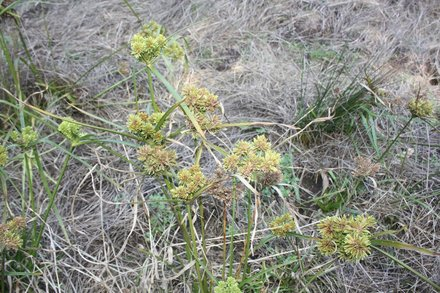
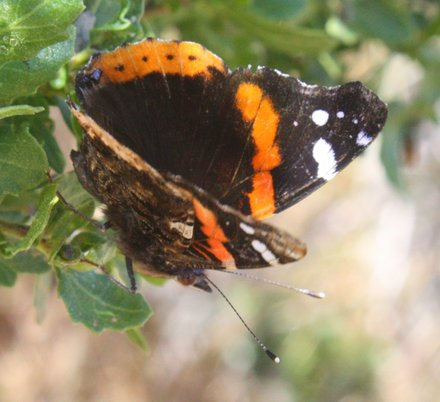
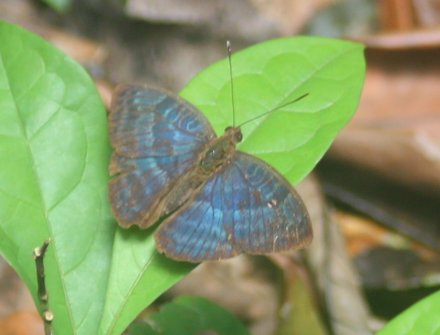
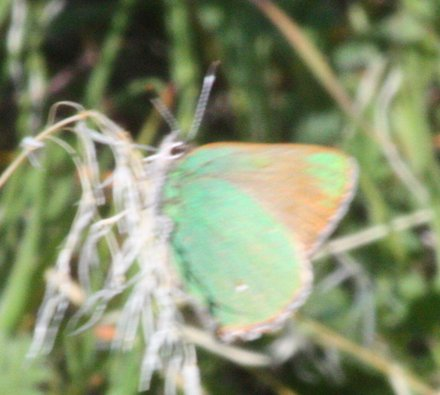
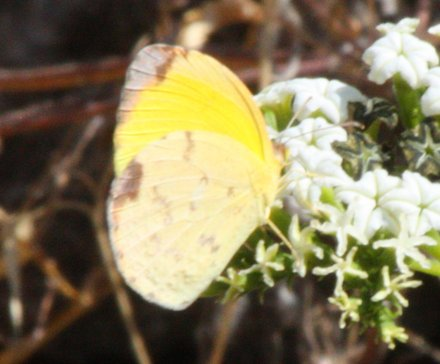
...
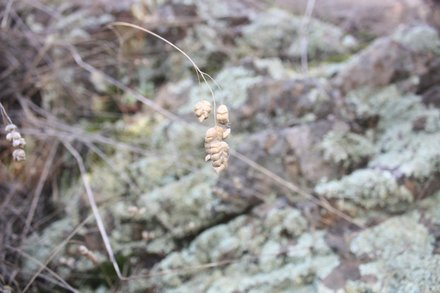
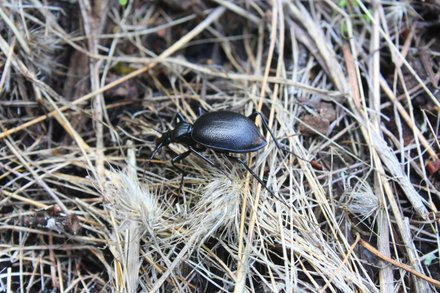
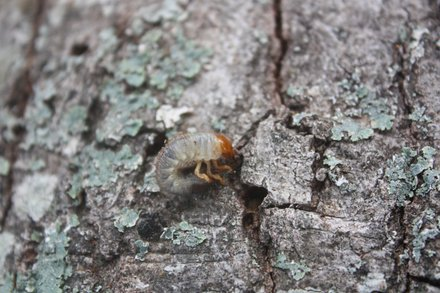
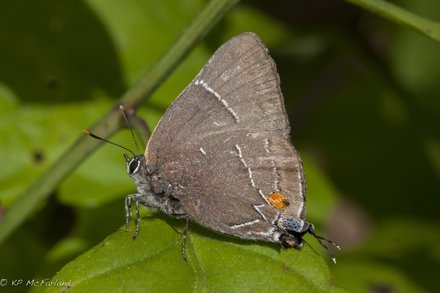
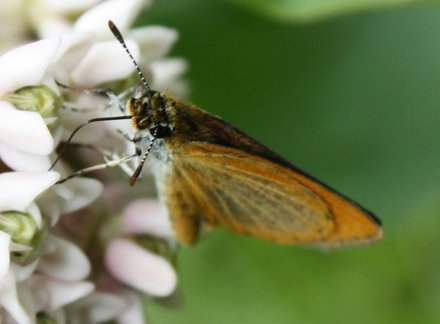

In [9]:
import base64
import json
from concurrent.futures import ThreadPoolExecutor
from io import BytesIO
from pathlib import Path
from threading import local

import requests
from IPython.display import HTML, display
from PIL import Image, ImageOps
from requests.adapters import HTTPAdapter
from urllib3.util import Retry

SUBMISSION = Path("/content/qwen3_vl_exam_yqij3_hs/submission.jsonl")
DATASET = Path("/content/dataset.jsonl")


def read_jsonl(path):
    return [
        json.loads(line)
        for line in path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]


predictions = read_jsonl(SUBMISSION)
urls = {row["photo_id"]: row["photo_url"] for row in read_jsonl(DATASET)}
prediction_ids = {row["photo_id"] for row in predictions}

if len(predictions) != 400 or len(prediction_ids) != 400 or prediction_ids != urls.keys():
    raise ValueError("Ожидались все 400 уникальных photo_id из dataset.jsonl.")

worker = local()


def load_preview(url):
    if not hasattr(worker, "session"):
        worker.session = requests.Session()
        retries = Retry(
            total=2,
            backoff_factor=0.5,
            status_forcelist=(429, 500, 502, 503, 504),
        )
        worker.session.mount("https://", HTTPAdapter(max_retries=retries))

    with worker.session.get(url, timeout=(8, 25)) as response:
        response.raise_for_status()
        with Image.open(BytesIO(response.content)) as original:
            preview = ImageOps.exif_transpose(original).convert("RGB")

    preview.thumbnail((440, 440), Image.Resampling.LANCZOS)
    buffer = BytesIO()
    preview.save(buffer, format="JPEG", quality=85)
    return base64.b64encode(buffer.getvalue()).decode("ascii")


def make_card(row):
    photo_id = row["photo_id"]
    boxes = row["boxes"]
    title = f"<div><b>{photo_id}</b> · рамок: {len(boxes)}</div>"

    try:
        photo = load_preview(urls[photo_id])
    except (requests.RequestException, OSError):
        return f"<div>{title}<p>Фото не загрузилось</p></div>"

    rectangles = []
    for box in boxes:
        left, top, width, height = (
            100 * box[key] for key in ("left", "top", "width", "height")
        )
        rectangles.append(
            '<div style="position:absolute;box-sizing:border-box;'
            f'left:{left}%;top:{top}%;width:{width}%;height:{height}%;'
            'border:2px solid #00c8ff;pointer-events:none"></div>'
        )

    return (
        f"<div>{title}<div style='position:relative;margin-top:4px'>"
        f"<img src='data:image/jpeg;base64,{photo}' "
        f"alt='Фото {photo_id}' style='display:block;width:100%;height:auto'>"
        f"{''.join(rectangles)}</div></div>"
    )


batch_size = 24
with ThreadPoolExecutor(max_workers=8) as pool:
    for start in range(0, len(predictions), batch_size):
        batch = predictions[start:start + batch_size]
        cards = "".join(pool.map(make_card, batch))
        display(HTML(
            '<div style="display:grid;grid-template-columns:'
            'repeat(auto-fit,minmax(220px,1fr));gap:14px;'
            f'align-items:start;margin-bottom:14px">{cards}</div>'
        ))